# 7. Conditional Edges & Branching/Routing

Every edge so far has been an **unconditional edge**: whatever a node does, the graph always proceeds to the same next node. This video is where the Applicant Screener stops being purely linear — `add_conditional_edges` lets the graph's path genuinely depend on runtime data, which is the concrete mechanism behind "workflows" (Video 1) and the actual payoff of the graph-vs-chain pitch (Video 2).

**Sections**
1. Recap: the utility + the Screener pipeline (Video 6's version, with `evaluation_notes`)
2. In-node `if`/`else` vs. graph-level conditional edges — the distinction that matters
3. `add_conditional_edges`: router function contract + mapping dict
4. Applying it: routing the Screener into `reject` / `interview` / `strong_match`
5. `Command`: combining a state update and a routing decision in one return value
6. Comparing both styles

## 1. Recap, and Priya's next complaint

**Priya's problem:** Hermione, Harry and Ron all go through the same pipeline and all get the same kind of answer: a score and a summary. But a score of 100 and a score of 2 should not lead to the same next step. She wants the Screener to *decide* what happens next.

- **Input:** a resume (we run all three candidates).
- **Output:** a `decision` (`reject`, `interview` or `strong_match`) plus a `summary` note for the hiring manager that explains it.

The summary node from Video 4 is back, but now it runs *after* the decision, so the note explains what was decided and why.

Same `llm_utils.py`, same `ScreenerState` with the `evaluation_notes` reducer from Video 6, plus new `decision` and `summary` fields. If you're running this notebook fresh, the cells below recreate everything up to (not including) today's routing.

In [ ]:
%pip install -r requirements.txt

In [ ]:
import os, getpass
from dotenv import load_dotenv

load_dotenv()

for env_var in ["ANTHROPIC_API_KEY", "OPENAI_API_KEY", "GOOGLE_API_KEY"]:
    if not os.environ.get(env_var):
        os.environ[env_var] = getpass.getpass(f"{env_var}: ")

In [1]:
import operator
from typing import Annotated, TypedDict
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

from llm_utils import call_llm

# The three candidates we follow through every notebook in this story.
RESUMES = {
    "Hermione": """
Hermione Granger
7 years of experience as a senior backend software engineer.
Skills: Python, distributed systems, SQL, PostgreSQL, Kubernetes, API design.
Led a 6-person platform team at a fintech company, mentoring junior engineers.
""",
    "Harry": """
Harry Potter
4 years of experience as a software developer.
Skills: Python, SQL, REST APIs.
Informally mentored two interns. No distributed systems or Kubernetes experience.
""",
    "Ron": """
Ron Weasley
8 months of experience as a junior web developer.
Skills: HTML, CSS, basic JavaScript.
No team or leadership experience.
""",
}

PARSE_SYSTEM_PROMPT = (
    "You extract structured fields from a resume. Reply with exactly four lines, "
    "no extra commentary:\n"
    "Name: <candidate name>\n"
    "Years: <years of experience as a number>\n"
    "Skills: <comma-separated skills>\n"
    "Leadership: <one short phrase on leadership or mentoring experience, or none>"
)

RUBRIC = (
    "Score the candidate from 0-100 against this fixed rubric:\n"
    "- 5+ years experience: up to 40 points\n"
    "- Skills overlap with [Python, distributed systems, Kubernetes, SQL]: up to 40 points\n"
    "- Leadership experience mentioned: up to 20 points\n"
    "Reply with exactly two lines, no extra commentary:\n"
    "Score: <integer 0-100>\n"
    "Rationale: <one sentence>"
)


def show_graph(graph):
    """Render a compiled graph. Falls back to Mermaid text if the PNG renderer is unavailable."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


class ScreenerState(TypedDict):
    resume_text: str
    candidate_name: str
    years_experience: str
    skills: str
    leadership: str
    score: int
    score_rationale: str
    decision: str
    summary: str
    evaluation_notes: Annotated[list[str], operator.add]


def parse_resume(state: ScreenerState) -> dict:
    result = call_llm("claude", messages=[{"role": "user", "content": state["resume_text"]}], system=PARSE_SYSTEM_PROMPT)
    fields = {"candidate_name": "", "years_experience": "", "skills": "", "leadership": ""}
    for line in result.content.strip().splitlines():
        if line.startswith("Name:"):
            fields["candidate_name"] = line.removeprefix("Name:").strip()
        elif line.startswith("Years:"):
            fields["years_experience"] = line.removeprefix("Years:").strip()
        elif line.startswith("Skills:"):
            fields["skills"] = line.removeprefix("Skills:").strip()
        elif line.startswith("Leadership:"):
            fields["leadership"] = line.removeprefix("Leadership:").strip()
    fields["evaluation_notes"] = [f"Parsed fields for {fields['candidate_name'] or 'candidate'}."]
    return fields


def score_against_rubric(state: ScreenerState) -> dict:
    candidate_summary = (
        f"Name: {state['candidate_name']}\n"
        f"Years of experience: {state['years_experience']}\n"
        f"Skills: {state['skills']}\n"
        f"Leadership: {state['leadership']}"
    )
    result = call_llm("claude", messages=[{"role": "user", "content": candidate_summary}], system=RUBRIC)
    score, rationale = 0, ""
    for line in result.content.strip().splitlines():
        if line.startswith("Score:"):
            score = int("".join(ch for ch in line if ch.isdigit()) or 0)
        elif line.startswith("Rationale:"):
            rationale = line.removeprefix("Rationale:").strip()
    return {
        "score": score,
        "score_rationale": rationale,
        "evaluation_notes": [f"Scored {score}/100: {rationale}"],
    }


def generate_summary(state: ScreenerState) -> dict:
    prompt = (
        f"Candidate: {state['candidate_name']}\n"
        f"Decision: {state['decision']}\n\n"
        "Write a two-sentence plain-text note for the hiring manager explaining this decision and the suggested next step."
    )
    result = call_llm("claude", messages=[{"role": "user", "content": prompt}])
    return {"summary": result.content}

## 2. In-node `if`/`else` vs. graph-level conditional edges

These solve different problems, and mixing them up is a common source of confusion:

- An `if`/`else` **inside a node** changes what that node *computes* — the graph's shape (which nodes exist, which edges connect them) stays exactly the same.
- A **conditional edge** changes which node *runs next* — the graph's path through its fixed shape depends on runtime state.

A quick, deliberately trivial illustration of the first kind — notice the graph itself never changes:

{'score': 85, 'tone_label': 'positive'}
{'score': 40, 'tone_label': 'neutral'}


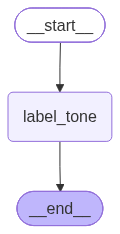

In [2]:
class ToneState(TypedDict):
    score: int
    tone_label: str


def label_tone(state: ToneState) -> dict:
    # In-node if/else: same single node, same edges either way.
    if state["score"] >= 70:
        return {"tone_label": "positive"}
    else:
        return {"tone_label": "neutral"}


tone_builder = StateGraph(ToneState)
tone_builder.add_node("label_tone", label_tone)
tone_builder.add_edge(START, "label_tone")
tone_builder.add_edge("label_tone", END)
tone_graph = tone_builder.compile()

print(tone_graph.invoke({"score": 85}))
print(tone_graph.invoke({"score": 40}))
show_graph(tone_graph)  # identical picture for both calls - only the DATA differed

Now the second kind: a conditional **edge**, where the graph's path itself forks. Section 4 applies this directly to the Screener; here's the mechanism in miniature first.

## 3. `add_conditional_edges`: router function contract + mapping dict

A router function takes the current state and returns a **string** (or list of strings) naming which node should run next. `add_conditional_edges(from_node, router_fn, mapping)` takes:
- the node whose outgoing edge is conditional,
- the router function,
- an optional **mapping dict** translating the router's return values to actual node names (useful when you want the router to return something more readable than exact node names, or route to the same node from multiple labels).

In [3]:
def route_by_score(state: ScreenerState) -> str:
    if state["score"] < 50:
        return "reject"
    elif state["score"] < 80:
        return "interview"
    else:
        return "strong_match"

## 4. Applying it: routing the Screener into `reject` / `interview` / `strong_match`

Each branch is its own (currently trivial) node producing a different final message, wired after `score_against_rubric` via `add_conditional_edges`:

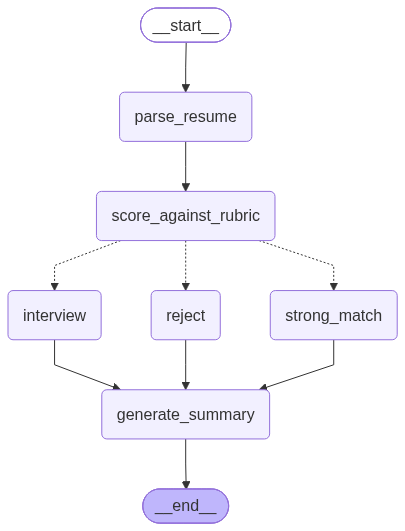

In [4]:
def reject_node(state: ScreenerState) -> dict:
    return {"decision": f"Not a match ({state['score']}/100): {state['score_rationale']}"}


def interview_node(state: ScreenerState) -> dict:
    return {"decision": f"Move to interview ({state['score']}/100): {state['score_rationale']}"}


def strong_match_node(state: ScreenerState) -> dict:
    return {"decision": f"Strong match ({state['score']}/100): {state['score_rationale']}"}


router_builder = StateGraph(ScreenerState)
router_builder.add_node("parse_resume", parse_resume)
router_builder.add_node("score_against_rubric", score_against_rubric)
router_builder.add_node("reject", reject_node)
router_builder.add_node("interview", interview_node)
router_builder.add_node("strong_match", strong_match_node)
router_builder.add_node("generate_summary", generate_summary)

router_builder.add_edge(START, "parse_resume")
router_builder.add_edge("parse_resume", "score_against_rubric")
router_builder.add_conditional_edges(
    "score_against_rubric",
    route_by_score,
    {"reject": "reject", "interview": "interview", "strong_match": "strong_match"},
)
router_builder.add_edge("reject", "generate_summary")
router_builder.add_edge("interview", "generate_summary")
router_builder.add_edge("strong_match", "generate_summary")
router_builder.add_edge("generate_summary", END)

router_screener_graph = router_builder.compile()
show_graph(router_screener_graph)

In [5]:
for name, resume in RESUMES.items():
    print(f"=== {name} ===")
    out = router_screener_graph.invoke({"resume_text": resume, "evaluation_notes": []})
    print(f"score: {out['score']}  |  decision: {out['decision']}")
    print(f"summary: {out['summary']}")
    print()

=== Hermione ===
score: 100  |  decision: Strong match (100/100): Candidate has 7 years of experience, matches all four key skills (Python, distributed systems, Kubernetes, SQL), and demonstrates clear leadership through leading and mentoring a 6-person team.
summary: Hermione Granger is a strong match for this role, bringing 7 years of experience and demonstrated proficiency in all four key skills—Python, distributed systems, Kubernetes, and SQL—along with proven leadership experience mentoring and leading a 6-person team. Given this excellent alignment with the role's requirements, we recommend moving forward quickly to schedule an interview.

=== Harry ===
score: 60  |  decision: Move to interview (60/100): Harry has 4 years of experience (slightly under 5), matches 2 of 4 key skills (Python, SQL), and shows informal leadership via mentoring interns.
summary: Harry Potter has 4 years of experience (just under our 5-year target), matches 2 of the 4 key skills (Python, SQL), and has s

Three candidates, three genuinely different paths. Hermione went to `strong_match`, Harry (borderline) to `interview`, and Ron to `reject`, and in each case only one of the three branches ever ran. The *picture* of the graph (Section 1's `show_graph`) shows all three branches because they're really there, even though only one executes per invocation. That's the thing an in-node `if`/`else` can't give you.

After the chosen branch, every path joins `generate_summary`, so Priya gets a note that explains the decision either way.

## 5. `Command`: combining a state update and a routing decision

`add_conditional_edges` keeps routing logic in a *separate* function from the node that produces the data the routing depends on. `Command(update=..., goto=...)` collapses both into a single return value from the node itself — increasingly the preferred style, and worth being comfortable with now because it becomes essential for human-in-the-loop routing in Video 18.

Rewrite `score_against_rubric` so it decides its own next step:

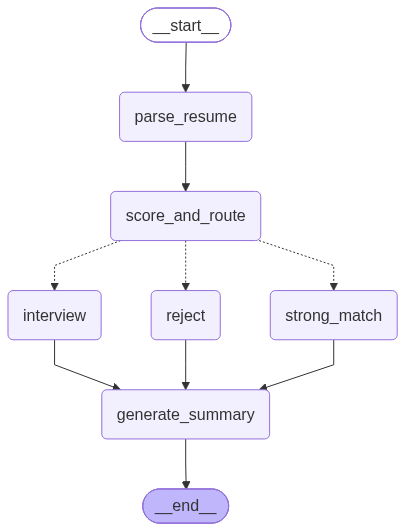

In [6]:
from langgraph.types import Command
from typing import Literal


def score_and_route(state: ScreenerState) -> Command[Literal["reject", "interview", "strong_match"]]:
    candidate_summary = (
        f"Name: {state['candidate_name']}\n"
        f"Years of experience: {state['years_experience']}\n"
        f"Skills: {state['skills']}\n"
        f"Leadership: {state['leadership']}"
    )
    result = call_llm("claude", messages=[{"role": "user", "content": candidate_summary}], system=RUBRIC)
    score, rationale = 0, ""
    for line in result.content.strip().splitlines():
        if line.startswith("Score:"):
            score = int("".join(ch for ch in line if ch.isdigit()) or 0)
        elif line.startswith("Rationale:"):
            rationale = line.removeprefix("Rationale:").strip()

    update = {
        "score": score,
        "score_rationale": rationale,
        "evaluation_notes": [f"Scored {score}/100: {rationale}"],
    }
    if score < 50:
        goto = "reject"
    elif score < 80:
        goto = "interview"
    else:
        goto = "strong_match"
    return Command(update=update, goto=goto)


command_builder = StateGraph(ScreenerState)
command_builder.add_node("parse_resume", parse_resume)
command_builder.add_node("score_and_route", score_and_route)
command_builder.add_node("reject", reject_node)
command_builder.add_node("interview", interview_node)
command_builder.add_node("strong_match", strong_match_node)
command_builder.add_node("generate_summary", generate_summary)

command_builder.add_edge(START, "parse_resume")
command_builder.add_edge("parse_resume", "score_and_route")
# No add_conditional_edges call at all - score_and_route's Command IS the routing decision.
command_builder.add_edge("reject", "generate_summary")
command_builder.add_edge("interview", "generate_summary")
command_builder.add_edge("strong_match", "generate_summary")
command_builder.add_edge("generate_summary", END)

command_screener_graph = command_builder.compile()
show_graph(command_screener_graph)

In [7]:
for name, resume in RESUMES.items():
    print(f"=== {name} ===")
    out = command_screener_graph.invoke({"resume_text": resume, "evaluation_notes": []})
    print(f"score: {out['score']}  |  decision: {out['decision']}")
    print(f"summary: {out['summary']}")
    print()

=== Hermione ===
score: 100  |  decision: Strong match (100/100): Candidate has 7 years of experience, all four target skills (Python, distributed systems, Kubernetes, SQL), and clear leadership experience leading and mentoring a team.
summary: Hermione Granger is a strong match for this role, bringing 7 years of relevant experience, proficiency in all four target skills (Python, distributed systems, Kubernetes, and SQL), and demonstrated leadership experience from leading and mentoring a team. Given this excellent alignment with the role's requirements, I recommend moving forward with scheduling an interview as soon as possible.

=== Harry ===
score: 58  |  decision: Move to interview (58/100): Harry has 4 years of experience (just under the 5-year threshold), matches 2 of 4 target skills (Python, SQL), and shows modest informal leadership through mentoring interns.
summary: Harry Potter scored 58/100 overall—just under the 5-year experience threshold with 4 years, and matched 2 of 4 

## 6. Comparing both styles

| | Router function + `add_conditional_edges` | `Command(update=..., goto=...)` |
|---|---|---|
| Where routing logic lives | Separate function from the node | Inside the node that produced the data |
| Graph definition | `add_conditional_edges("score_against_rubric", route_by_score, {...})` | Plain `add_node`, no conditional-edges call |
| Best when | Routing logic is reused across multiple nodes, or you want it visually/structurally separate | The node computing the decision *is* the natural place to decide where to go |

Both compiled graphs route each candidate to the same branch and produce an equivalent `decision` field — this is a style choice, not a behavior difference, for routing this simple.

**Explicitly still ahead:** this routing is still **acyclic** — Video 8 adds loops that route *backward* to an earlier node (a bounded retry pattern); Video 9 adds *parallel* branches that all execute, rather than choosing exactly one; Video 18 is where `Command`'s `goto` becomes essential, for resuming a graph at a human-chosen node after an `interrupt()`.

**Next video** covers loops. Priya has noticed that Harry's score sits close to a line, and she doesn't want to make a call on a borderline candidate from a single reading. We'll route backward to an earlier node for a second look, with an explicit iteration cap and `recursion_limit` as the safety net against infinite cycles.